# Clasificación de textos en Esperanto

**Minería de Textos · CUNEF · 2026/2027**

Clasificamos párrafos en esperanto en tres temas de transporte: **ferrocarril** (`fervojo`),
**automóvil** (`automobilo`) y **aviación** (`aviado`). El cuaderno sigue las tres fases de la práctica:

1. **Dataset**: párrafos de la Wikipedia en esperanto etiquetados por tema.
2. **NLP**: nuestro propio modelo de NLP basado en reglas, con una API parecida a la de spaCy.
3. **Clasificación**: vectorizamos el dataset, entrenamos un modelo y lo probamos con páginas web.

## 0. Configuración

Con `GENERAR_DATASET = False` se carga el CSV que ya tenemos subido en GitHub (es más rápido y
siempre da el mismo resultado). Con `True` se vuelve a descargar todo de la Wikipedia.

In [1]:
GENERAR_DATASET = False

URL_DATASET = "https://raw.githubusercontent.com/guilletaff/Clasificacion_Textos_Esperanto/main/data/dataset_esperanto.csv"
URL_STOPWORDS = "https://raw.githubusercontent.com/jparisu/nlp-esperantilo/main/resources/esperanto/vortoj.json"

import re
import sys
import json
import time
import subprocess
from collections import Counter
from functools import lru_cache

import requests
import pandas as pd
import matplotlib.pyplot as plt

# Fase 1 · Dataset

## 1.1 Temas y artículos

Elegimos tres temas de transporte porque comparten bastante vocabulario (`motoro`, `rapido`,
`pasaĝero`, `veturilo`...) y así la clasificación no es trivial. Para cada tema escogimos a mano
artículos de la Wikipedia en esperanto.

In [2]:
CATEGORIAS = {
    "fervojo": [            # ferrocarril
        "Fervojo", "Lokomotivo", "Metroo", "Tramo", "Rapidtrajno", "Vagono",
        "Fervoja stacio", "Elektra lokomotivo", "Dizel-lokomotivo", "Maglevo",
        # añadidos para tener más párrafos de esta clase
        "Trajno", "Stacidomo", "Vaporlokomotivo", "Altrapida fervojo", "Funikularo",
    ],
    "automobilo": [         # automóvil
        "Aŭtomobilo", "Kamiono", "Aŭtobuso", "Elektra aŭtomobilo", "Motociklo",
        "Eksplodmotoro", "Taksio", "Aŭtovojo", "Sportaŭto", "Karoserio",
    ],
    "aviado": [             # aviación
        "Aviadilo", "Aviado", "Flughaveno", "Helikoptero", "Jetmotoro",
        "Komerca aviado", "Boeing 747", "Supersona aviadilo", "Flugkompanio", "Aeronaŭtiko",
        "Piloto", "Airbus", "Concorde",
    ],
}

## 1.2 Descarga de los artículos

Usamos `WikiPage`, de la librería del repositorio guía (`esperantilo`). Si no se puede instalar,
pedimos el texto directamente a la API de la Wikipedia con `requests`, para que el cuaderno no se
pare.

Un detalle importante: si un título no existe en esperanto, `WikiPage` lo busca por defecto en
español e inglés y, si no, en cualquier idioma. En la primera versión del dataset se nos colaron
así párrafos en español (de *Komerca aviado* y *Supersona aviadilo*). Por eso le pasamos
`fallback_languages=()` y `any_language=False`, y comprobamos que la página devuelta esté en
esperanto.

In [3]:
def cargar_esperantilo():
    # Devuelve la clase WikiPage, o None si no se consigue instalar la librería
    try:
        from esperantilo import WikiPage
        return WikiPage
    except ImportError:
        pass
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/jparisu/nlp-esperantilo.git"], check=True, timeout=300)
        from esperantilo import WikiPage
        return WikiPage
    except Exception as e:
        print("No se pudo instalar esperantilo, se usará la API de Wikipedia:", e)
        return None


def descargar_articulo(titulo, WikiPage=None):
    if WikiPage is not None:
        # Solo esperanto: sin idiomas de respaldo ni búsqueda en otros idiomas
        pagina = WikiPage.look_up(titulo, language="eo", fallback_languages=(), any_language=False)
        if pagina.language != "eo":
            raise ValueError(f"solo existe en '{pagina.language}'")
        return pagina.full_text()

    # Alternativa: API de MediaWiki
    respuesta = requests.get(
        "https://eo.wikipedia.org/w/api.php",
        params={"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1,
                "titles": titulo, "format": "json", "formatversion": 2},
        headers={"User-Agent": "practica-mineria-textos-cunef"},
        timeout=20,
    )
    respuesta.raise_for_status()
    pagina = respuesta.json()["query"]["pages"][0]
    if "missing" in pagina:
        raise ValueError("el artículo no existe")
    return pagina["extract"]

## 1.3 Párrafos y limpieza

Cada artículo se corta por saltos de línea (una línea = un párrafo) y cada párrafo se limpia:
quitamos los títulos de sección (`== Historio ==`), las referencias tipo `[1]`, las URLs y el
carácter `;`, que es el separador del CSV.

Cada párrafo hereda la etiqueta de su artículo.

In [4]:
def limpiar_parrafo(texto):
    texto = re.sub(r"==+.*?==+", "", texto)                # títulos de sección
    texto = re.sub(r"\[\d+\]", "", texto)                  # referencias [1], [2]...
    texto = re.sub(r"https?://\S+|www\.\S+", "", texto)    # enlaces
    texto = texto.replace(";", ",")                        # ';' rompería el CSV
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


def construir_dataset():
    WikiPage = cargar_esperantilo()
    filas = []
    for categoria, titulos in CATEGORIAS.items():
        print(f"--- {categoria} ---")
        for titulo in titulos:
            try:
                texto = descargar_articulo(titulo, WikiPage)
                parrafos = [limpiar_parrafo(p) for p in texto.split("\n")]
                parrafos = [p for p in parrafos if p]
                filas += [{"text": p, "class": categoria} for p in parrafos]
                print(f"  {titulo}: {len(parrafos)} párrafos")
            except Exception as e:
                # si un artículo falla seguimos con el resto
                print(f"  {titulo}: ERROR ({e})")
            time.sleep(1)   # para no saturar la API
    return pd.DataFrame(filas, columns=["text", "class"])

## 1.4 Filtrado del ruido

Revisando el CSV vimos que muchos "párrafos" no son texto útil. Los descartamos con reglas
sencillas:

| Motivo | Regla | Ejemplo |
|---|---|---|
| Muy corto | menos de 40 caracteres | títulos sueltos |
| Bibliografía | contiene `ISBN`, `Arkivigite` o `Wayback` | `Ernst Götsch: Luftfahrzeugtechnik ... ISBN 3-613-02006-8` |
| Otro idioma | 2 o más palabras típicas de español, inglés o alemán (`que`, `los`, `the`, `und`...) | `La aviación de transporte regular comercial es una actividad...` |
| Elemento de lista | menos de 100 caracteres y ningún verbo conjugado (`-as`, `-is`, `-os`, `-us`) | `Internacia flughaveno Mariupol (Mariupolo)` |
| Duplicado | texto repetido | |

Estas reglas se aplican tanto si generamos el dataset como si lo cargamos de GitHub.

In [5]:
LONGITUD_MINIMA = 40
PALABRAS_OTROS_IDIOMAS = {"que", "los", "las", "del", "una", "y", "the", "and", "of", "with",
                          "und", "der", "die", "das", "für"}


def motivo_descarte(texto):
    # Devuelve por qué se descarta un párrafo, o None si es válido
    if len(texto) < LONGITUD_MINIMA:
        return "muy corto"
    if re.search(r"ISBN|Arkivigite|Wayback", texto):
        return "bibliografía"
    palabras = re.findall(r"\w+", texto.lower())
    if sum(p in PALABRAS_OTROS_IDIOMAS for p in palabras) >= 2:
        return "otro idioma"
    if len(texto) < 100 and not re.search(r"\w(as|is|os|us)\b", texto):
        return "elemento de lista"
    return None


def filtrar_dataset(df):
    df = df.copy()
    df["text"] = df["text"].map(limpiar_parrafo)
    df["motivo"] = df["text"].map(motivo_descarte)
    df.loc[df["motivo"].isna() & df["text"].duplicated(), "motivo"] = "duplicado"

    print("Párrafos descartados por clase y motivo:")
    print(pd.crosstab(df["class"], df["motivo"].fillna("válido"), margins=True), "\n")

    return df[df["motivo"].isna()][["text", "class"]].reset_index(drop=True)

## 1.5 Generar o cargar el dataset

In [6]:
def cargar_dataset_guardado():
    # Primero de GitHub; si falla, de una copia local
    for ruta in [URL_DATASET, "../data/dataset_esperanto.csv", "dataset_esperanto.csv"]:
        try:
            return pd.read_csv(ruta, sep=";", encoding="utf-8")
        except Exception as e:
            print(f"No se pudo leer {ruta}: {e}")
    raise RuntimeError("No se encontró el dataset")


generado = False
if GENERAR_DATASET:
    df_bruto = construir_dataset()
    # si falla la descarga de alguna clase entera, usamos el dataset guardado
    generado = df_bruto["class"].nunique() == len(CATEGORIAS)
    if not generado:
        print("Faltan clases en el dataset generado, se usa el guardado en GitHub")
if not generado:
    df_bruto = cargar_dataset_guardado()

print("Párrafos antes de filtrar:", len(df_bruto))
df = filtrar_dataset(df_bruto)

if generado:
    df.to_csv("dataset_esperanto.csv", sep=";", index=False, encoding="utf-8")
    print("Dataset guardado en dataset_esperanto.csv")

# Comprobamos el contrato de datos
assert list(df.columns) == ["text", "class"]
assert not df["text"].str.contains(";").any()

print("Párrafos después de filtrar:", len(df))
print(df["class"].value_counts())
df.head()

Párrafos antes de filtrar: 657
Párrafos descartados por clase y motivo:
motivo      bibliografía  duplicado  elemento de lista  muy corto  \
class                                                               
automobilo            18          0                 39          0   
aviado                15          0                 92          3   
fervojo               10          2                 32          0   
All                   43          2                163          3   

motivo      otro idioma  válido  All  
class                                 
automobilo            2     205  264  
aviado               14     122  246  
fervojo               5      98  147  
All                  21     425  657   

Párrafos después de filtrar: 425
class
automobilo    205
aviado        122
fervojo        98
Name: count, dtype: int64


,text,class
0,"Fervojo estas transportsistemo, en kiu la vetu...",fervojo
1,La rado-relo-sistemo distingas fervojon de mag...,fervojo
2,Transkontinenta fervojo estas sinsekva fervojo...,fervojo
3,Altrapida fervojo estas fervojo kun vojaĝa rap...,fervojo
4,István Gulyás en sia artikolo Pri la faka agad...,fervojo


**Conclusiones de la Fase 1.** Casi un tercio de las líneas que devuelve la Wikipedia no son
párrafos útiles: sobre todo listas (por ejemplo, la lista de aeropuertos del artículo
*Flughaveno*) y bibliografía. Además, aunque un párrafo pase los filtros, la etiqueta heredada del
artículo no siempre es correcta: hay frases genéricas ("Ĝi estis fondita en 1950") o que hablan de
otro tema (un párrafo sobre turbinas de gas dentro del artículo de motores de coche). En la
sección 2.6 usamos el modelo de NLP para medir parte de ese ruido.

# Fase 2 · Modelo de NLP para Esperanto

Construimos el modelo desde cero, solo con Python estándar (sin spaCy, NLTK ni similares).
Se basa en reglas porque el esperanto es muy regular: **la terminación de una palabra dice qué
tipo de palabra es**.

| Terminación | Categoría | Ejemplo |
|---|---|---|
| `-o` | sustantivo | `trajno` (tren) |
| `-a` | adjetivo | `rapida` (rápido) |
| `-e` | adverbio | `rapide` (rápidamente) |
| `-i` | verbo en infinitivo | `veturi` (viajar) |
| `-as` / `-is` / `-os` | verbo en presente / pasado / futuro | `veturis` |
| `-us` / `-u` | condicional / imperativo | `veturus` |
| `-j` | plural | `trajnoj` |
| `-n` | acusativo (complemento directo) | `trajnon` |
| `-ant-`, `-int-`, `-ont-`, `-at-`, `-it-`, `-ot-` | participios | `konstruita` (construido) |

Lo único que no sigue estas reglas es un grupo pequeño y cerrado de palabras (artículo,
pronombres, preposiciones, conjunciones...), que guardamos en un **léxico**.

El modelo funciona como spaCy: `doc = nlp(texto)` devuelve un `Doc` formado por `Token`s, y cada
token tiene `text`, `lemma_`, `pos_`, `morph` e `is_stop`. Para el POS usamos las etiquetas
universales que usa spaCy (`NOUN`, `VERB`, `ADJ`...).

## 2.1 Léxico de palabras cerradas

Guardamos cada palabra con su categoría y su lema. Los pronombres y la tabla de correlativos
(`ki-`, `ti-`, `i-`, `ĉi-`, `neni-` combinados con `-u`, `-o`, `-a`, `-e`, `-am`...) los
generamos con bucles en lugar de escribir todas sus formas (`kiu`, `kiuj`, `kiun`, `kiujn`...).

In [7]:
PRONOMBRES = ["mi", "ci", "vi", "li", "ŝi", "ĝi", "ni", "ili", "oni", "si"]

INICIOS_CORRELATIVOS = ["ki", "ti", "i", "ĉi", "neni"]
FINALES_CORRELATIVOS = {"u": "PRON", "o": "PRON", "a": "DET", "es": "DET",
                        "e": "ADV", "am": "ADV", "el": "ADV", "al": "ADV", "om": "ADV"}

PREPOSICIONES = {"al", "anstataŭ", "antaŭ", "apud", "ĉe", "ĉirkaŭ", "da", "de", "dum", "ekde",
                 "ekster", "el", "en", "ĝis", "inter", "je", "kontraŭ", "krom", "kun", "laŭ",
                 "malantaŭ", "malgraŭ", "per", "po", "por", "post", "preter", "pri", "pro",
                 "sen", "sub", "super", "sur", "tra", "trans"}
CONJUNCIONES = {"kaj", "aŭ", "sed", "nek"}
CONJUNCIONES_SUB = {"ke", "se", "ĉar", "kvankam", "kvazaŭ", "ol"}
PARTICULAS = {"ne", "ja", "jen", "ajn", "ĉi", "ĉu", "ju", "des", "mem"}
ADVERBIOS = {"ankaŭ", "ankoraŭ", "almenaŭ", "apenaŭ", "baldaŭ", "hieraŭ", "hodiaŭ", "morgaŭ",
             "preskaŭ", "nun", "jam", "tre", "tro", "tuj", "for", "plu", "pli", "plej", "nur",
             "eĉ", "ĵus", "do", "tamen", "ambaŭ", "jes"}
INTERJECCIONES = {"adiaŭ", "ha", "he", "ho", "hu", "nu", "ve", "fi", "hura"}
NUMEROS = {"nul", "unu", "du", "tri", "kvar", "kvin", "ses", "sep", "ok", "naŭ", "dek", "cent", "mil"}
AUXILIARES = {"esti", "povi", "devi", "voli"}


def crear_lexico():
    lexico = {}   # palabra -> (pos, lema)

    def añadir(palabra, pos, lema):
        lexico.setdefault(palabra, (pos, lema))

    añadir("la", "DET", "la")
    añadir("l'", "DET", "la")

    for p in PRONOMBRES:
        añadir(p, "PRON", p)
        añadir(p + "n", "PRON", p)                 # acusativo: lin
        for fin in ["a", "aj", "an", "ajn"]:       # posesivos: lia, liaj, lian, liajn
            añadir(p + fin, "DET", p + "a")

    for inicio in INICIOS_CORRELATIVOS:
        for final, pos in FINALES_CORRELATIVOS.items():
            base = inicio + final
            añadir(base, pos, base)
            if final in ("u", "a"):                # kiuj, kiun, kiujn
                for extra in ["j", "n", "jn"]:
                    añadir(base + extra, pos, base)
            elif final in ("o", "e"):              # kion, kien
                añadir(base + "n", pos, base)

    for grupo, pos in [(PREPOSICIONES, "ADP"), (CONJUNCIONES, "CCONJ"),
                       (CONJUNCIONES_SUB, "SCONJ"), (PARTICULAS, "PART"),
                       (ADVERBIOS, "ADV"), (INTERJECCIONES, "INTJ"), (NUMEROS, "NUM")]:
        for palabra in grupo:
            añadir(palabra, pos, palabra)
    return lexico


LEXICO = crear_lexico()
CORRELATIVOS_U = {i + "u" for i in INICIOS_CORRELATIVOS}   # kiu, tiu, iu, ĉiu, neniu
print("Palabras en el léxico:", len(LEXICO))

Palabras en el léxico: 248


## 2.2 Stop-words

Partimos de la lista `vortoj.json` del repositorio guía y nos quedamos con las palabras marcadas
como `"ignorinda": true`. Si no se puede descargar, usamos una copia que llevamos en el cuaderno.

Le añadimos lo que le falta: los correlativos (`kiu`, `tio`, `ĉiuj`...), todas las palabras de
nuestro léxico y los verbos auxiliares. Además comprobamos tanto la palabra como su lema, así
`estas` y `estis` cuentan como stop-words porque su lema es `esti`.

In [8]:
COPIA_STOPWORDS = set('''
adiaŭ ajn al ankaŭ ankoraŭ anstataŭ antaŭ apenaŭ apud aŭ baldaŭ bonvoli cent ci da de dek
des do doktoro du dum ekster ekzemple el en esti eĉ eble for fraŭlo ha havi he hieraŭ ho
hodiaŭ hu ili inter ja jam je jen jes ju kaj ke kontraŭ krom kun kvankam kvar kvazaŭ kvin la
laŭ li male malgraŭ mem mi mil minus morgaŭ naŭ ne nek nepre ni nu nul nun nur ok ol oni per
plej pli plu plus po por post povi preskaŭ preter pri pro se sed sen sep ses si sinjoro sub
super supre sur tamen tra trans tre tri tro tuj tute unu ve verŝajne vi ĉar ĉe ĉi ĉirkaŭ ĉu
ĝi ĝis ĵus ŝi
'''.split())


def cargar_stopwords():
    try:
        datos = requests.get(URL_STOPWORDS, timeout=10).json()
        stopwords = {e["vorto"] for e in datos["vortoj"] if e.get("ignorinda")}
        print("Stop-words descargadas de GitHub")
    except Exception as e:
        print("No se pudo descargar vortoj.json, usamos la copia:", e)
        stopwords = set(COPIA_STOPWORDS)

    stopwords |= {lema for pos, lema in LEXICO.values()}   # correlativos, preposiciones...
    stopwords |= AUXILIARES
    return stopwords


STOP_WORDS = cargar_stopwords()
print("Total de stop-words:", len(STOP_WORDS))

Stop-words descargadas de GitHub
Total de stop-words: 185


## 2.3 Clases `Token` y `Doc`

Igual que en spaCy: un `Doc` es la lista de `Token`s de un texto. Se puede recorrer con un `for`,
acceder por posición (`doc[0]`) y sacar un trozo (`doc[1:4]`).

In [9]:
class Token:
    def __init__(self, text, i):
        self.text = text      # texto original
        self.i = i            # posición dentro del Doc
        self.lemma_ = ""
        self.pos_ = ""
        self.morph = {}       # rasgos morfológicos: número, caso, tiempo...
        self.is_stop = False

    @property
    def is_punct(self):
        return self.pos_ == "PUNCT"

    @property
    def is_alpha(self):
        return self.text.isalpha()

    def __repr__(self):
        return self.text


class Doc:
    def __init__(self, text, tokens):
        self.text = text
        self.tokens = tokens

    def __iter__(self):
        return iter(self.tokens)

    def __len__(self):
        return len(self.tokens)

    def __getitem__(self, i):
        return self.tokens[i]

    def tabla(self):
        # Análisis de cada token en forma de tabla
        return pd.DataFrame([{"text": t.text, "lemma": t.lemma_, "pos": t.pos_,
                              "morph": t.morph, "is_stop": t.is_stop} for t in self.tokens])

    def __repr__(self):
        return self.text

## 2.4 Tokenizador

Una expresión regular que reconoce, en este orden: URLs, números (`1950`, `3,5` y también
ordinales como `20-a`), palabras (con letras del esperanto `ĉ ĝ ĥ ĵ ŝ ŭ` y compuestos con guion
como `Dizel-lokomotivo`) y cualquier signo de puntuación suelto.

In [10]:
PATRON_TOKENS = re.compile(r'''
      https?://\S+ | www\.\S+              # URLs
    | \d+(?:[.,]\d+)*(?:-[a-zĉĝĥĵŝŭ]+)?     # números: 1950, 3,5, 20-a
    | [lL]'(?=\s)                          # artículo abreviado: l'
    | [^\W\d_][^\W_]*(?:-[^\W_]+)*          # palabras, también con guion
    | [^\w\s]                              # signos de puntuación
''', re.VERBOSE)


def tokenizar(texto):
    return PATRON_TOKENS.findall(texto)


tokenizar("La Dizel-lokomotivo veturis je 120 km/h en la 20-a jarcento.")

['La',
 'Dizel-lokomotivo',
 'veturis',
 'je',
 '120',
 'km',
 '/',
 'h',
 'en',
 'la',
 '20-a',
 'jarcento',
 '.']

## 2.5 Análisis de cada palabra: POS, lema y morfología

`analizar_palabra()` mira una palabra (en minúsculas) y devuelve su categoría, su lema y sus
rasgos. Las reglas se prueban en orden:

1. Si está en el **léxico**, se usa lo que dice el léxico.
2. **Números**: en cifras (`1950`), ordinales en cifras (`20-a`) y compuestos (`dudek` = 20).
3. **Palabras extranjeras**: si tiene alguna letra que no existe en esperanto (`q`, `w`, `x`, `y`,
   `é`, `ó`...), es una palabra de otro idioma (`X`).
4. **Participios**: `konstruita` → lema `konstrui`. Hay palabras que parecen participios pero no lo
   son (`konstanta`, `brita`, `privata`...); las fuimos encontrando al revisar el corpus y las
   guardamos en una lista de excepciones.
5. **Verbos**: `-as`, `-is`, `-os`, `-us`, `-u`, `-i` → lema en `-i`.
6. **Sustantivos**, **adjetivos** y **adverbios** por su terminación.
7. Si nada encaja, `X`.

**Lematizar** en esperanto es cambiar la terminación por la de diccionario: `trajnojn` → `trajno`,
`rapidaj` → `rapida`, `veturis` → `veturi`.

Usamos `lru_cache` para no analizar dos veces la misma palabra, porque en el corpus se repiten
mucho.

In [11]:
ALFABETO = set("abcĉdefgĝhĥijĵklmnoprsŝtuŭvz")

# Raíces que parecen participios pero no lo son (konst-anta, br-ita, priv-ata...)
NO_PARTICIPIOS = {
    "konst", "gig", "eleg", "elef", "horiz", "aŭtom", "priv", "apar", "klim", "sold", "kandid",
    "rezult", "sen", "kval", "pil", "rob", "patri", "idi", "diam", "mil", "parazi", "str",
    "ril", "jezui", "fosf", "merk", "adiab", "bo", "profi", "sport", "kroko", "demokr",
    "ŝt", "fr", "br", "gr", "pl", "sp", "tr", "kv", "fl", "oh",
}

TIEMPOS = {"as": "presente", "is": "pasado", "os": "futuro", "us": "condicional",
           "u": "imperativo", "i": "infinitivo"}
PARTICIPIOS = {"ant": "activo presente", "int": "activo pasado", "ont": "activo futuro",
               "at": "pasivo presente", "it": "pasivo pasado", "ot": "pasivo futuro"}


def numero_y_caso(final):
    # A partir de -j y -n: trajnojn -> plural, acusativo
    return {"numero": "plural" if "j" in final else "singular",
            "caso": "acusativo" if final.endswith("n") else "nominativo"}


@lru_cache(maxsize=None)
def analizar_palabra(palabra):
    # 1. Léxico
    if palabra in LEXICO:
        pos, lema = LEXICO[palabra]
        return pos, lema, {}

    # 2. Números
    if re.fullmatch(r"\d+(?:[.,]\d+)*", palabra):
        return "NUM", palabra, {}
    if re.fullmatch(r"\d+-aj?n?", palabra):                    # 20-a, 1950-aj
        return "ADJ", palabra, {}
    if re.fullmatch(r"(?:(?:du|tri|kvar|kvin|ses|sep|ok|naŭ)?(?:dek|cent|mil))+", palabra):
        return "NUM", palabra, {}                                 # dudek, tricent...

    # 3. Palabras extranjeras
    if any(c.isalpha() and c not in ALFABETO for c in palabra):
        return "X", palabra, {}

    # 4. Participios adjetivales y adverbiales
    m = re.fullmatch(r"(.{2,}?)(ant|int|ont|at|it|ot)(a|aj|an|ajn|e)", palabra)
    if m and m.group(1) not in NO_PARTICIPIOS:
        raiz, sufijo, final = m.groups()
        morph = {"participio": PARTICIPIOS[sufijo]}
        if final == "e":
            return "ADV", raiz + "i", morph
        return "ADJ", raiz + "i", {**morph, **numero_y_caso(final)}

    # 5. Verbos
    m = re.fullmatch(r"(.{2,}?)(as|is|os|us|u|i)", palabra)
    if m:
        raiz, final = m.groups()
        pos = "AUX" if raiz + "i" in AUXILIARES else "VERB"
        return pos, raiz + "i", {"tiempo": TIEMPOS[final]}

    # 6. Sustantivos, adjetivos y adverbios
    m = re.fullmatch(r"(.+?)(o|oj|on|ojn)", palabra)
    if m:
        return "NOUN", m.group(1) + "o", numero_y_caso(m.group(2))
    m = re.fullmatch(r"(.+?)(a|aj|an|ajn)", palabra)
    if m:
        return "ADJ", m.group(1) + "a", numero_y_caso(m.group(2))
    m = re.fullmatch(r"(.+?)(e|en)", palabra)
    if m:
        return "ADV", m.group(1) + "e", {}                        # hejmen -> hejme
    if palabra.endswith("aŭ") and len(palabra) > 3:
        return "ADV", palabra, {}

    # 7. No reconocida
    return "X", palabra, {}


for p in ["trajnojn", "rapidaj", "veturis", "konstruita", "konstanta", "kiujn", "dudek", "aviación"]:
    print(f"{p:<12}", analizar_palabra(p))

trajnojn     ('NOUN', 'trajno', {'numero': 'plural', 'caso': 'acusativo'})
rapidaj      ('ADJ', 'rapida', {'numero': 'plural', 'caso': 'nominativo'})
veturis      ('VERB', 'veturi', {'tiempo': 'pasado'})
konstruita   ('ADJ', 'konstrui', {'participio': 'pasivo pasado', 'numero': 'singular', 'caso': 'nominativo'})
konstanta    ('ADJ', 'konstanta', {'numero': 'singular', 'caso': 'nominativo'})
kiujn        ('PRON', 'kiu', {})
dudek        ('NUM', 'dudek', {})
aviación     ('X', 'aviación', {})


## 2.6 Reglas de contexto

Algunas cosas no se pueden saber mirando la palabra sola, así que después del análisis aplicamos
unas pocas reglas que miran a los vecinos:

* **Nombres propios**: una palabra en mayúscula que no está al principio de la frase (`en Francio`,
  `de Airbus`) o que es una sigla (`TGV`) es `PROPN`. Su lema conserva la mayúscula y pierde el
  acusativo: `Francion` → `Francio`.
* **Correlativos en `-u`** (`tiu`, `kiu`...): son determinante si van delante de un sustantivo o
  adjetivo (`tiu trajno`) y pronombre si no (`kiu venis?`).
* **`povi`, `devi`, `voli`**: son auxiliares solo si les sigue un infinitivo (`ni povas veturi`);
  si no, son verbos normales (`ni volas pacon`).

In [12]:
def es_inicio_de_frase(doc, i):
    return i == 0 or doc[i - 1].text in {".", "!", "?", ":"}


def etiquetar(doc):
    # Primero cada palabra por separado
    for t in doc:
        if not any(c.isalnum() for c in t.text):
            t.pos_, t.lemma_ = "PUNCT", t.text
            continue
        if t.text.startswith(("http", "www")):
            t.pos_, t.lemma_ = "X", t.text
            continue
        t.pos_, t.lemma_, t.morph = analizar_palabra(t.text.lower())

    # Después, las reglas de contexto
    for i, t in enumerate(doc):
        siguiente = doc[i + 1] if i + 1 < len(doc) else None

        # Nombres propios
        if t.text[0].isupper() and t.text.lower() not in LEXICO:
            sigla = t.text.isupper() and len(t.text) > 1
            if sigla or t.pos_ == "X" or not es_inicio_de_frase(doc, i):
                t.pos_ = "PROPN"
                t.lemma_ = re.sub(r"(o|oj)n$", r"\1", t.text)    # Francion -> Francio
                t.lemma_ = re.sub(r"oj$", "o", t.lemma_)
                t.morph = {}

        # Correlativos en -u: determinante o pronombre
        if t.lemma_ in CORRELATIVOS_U:
            t.pos_ = "DET" if siguiente and siguiente.pos_ in ("NOUN", "ADJ", "PROPN") else "PRON"

        # povi / devi / voli: auxiliar solo si va seguido de infinitivo
        if t.pos_ == "AUX" and t.lemma_ != "esti":
            siguientes = [u for u in doc.tokens[i + 1:i + 4] if u.pos_ not in ("ADV", "PART")]
            if not (siguientes and siguientes[0].morph.get("tiempo") == "infinitivo"):
                t.pos_ = "VERB"
    return doc


def marcar_stopwords(doc):
    for t in doc:
        t.is_stop = t.text.lower() in STOP_WORDS or t.lemma_.lower() in STOP_WORDS
    return doc

## 2.7 La clase `Esperanto` (el `nlp` de spaCy)

Junta todo: tokeniza el texto, crea el `Doc` y le pasa los componentes del pipeline en orden.

In [13]:
class Esperanto:
    def __init__(self):
        self.pipeline = [("tagger", etiquetar), ("stopwords", marcar_stopwords)]

    @property
    def pipe_names(self):
        return [nombre for nombre, _ in self.pipeline]

    def __call__(self, texto):
        palabras = tokenizar(texto)
        doc = Doc(texto, [Token(p, i) for i, p in enumerate(palabras)])
        for _, componente in self.pipeline:
            doc = componente(doc)
        return doc

    def pipe(self, textos):
        # Para procesar muchos textos seguidos, como nlp.pipe() de spaCy
        for texto in textos:
            yield self(texto)


nlp = Esperanto()
nlp.pipe_names

['tagger', 'stopwords']

### Ejemplo de uso

In [14]:
doc = nlp("La rapidaj elektraj trajnoj veturis inter Parizo kaj Liono, kaj la "
          "konstruita flughaveno povos akcepti multajn aviadilojn.")
doc.tabla()

,text,lemma,pos,morph,is_stop
0,La,la,DET,{},True
1,rapidaj,rapida,ADJ,"{'numero': 'plural', 'caso': 'nominativo'}",False
2,elektraj,elektra,ADJ,"{'numero': 'plural', 'caso': 'nominativo'}",False
3,trajnoj,trajno,NOUN,"{'numero': 'plural', 'caso': 'nominativo'}",False
4,veturis,veturi,VERB,{'tiempo': 'pasado'},False
5,inter,inter,ADP,{},True
6,Parizo,Parizo,PROPN,{},False
7,kaj,kaj,CCONJ,{},True
8,Liono,Liono,PROPN,{},False
9,",",",",PUNCT,{},False


In [15]:
for token in nlp("Tiu aŭto, kiun mi aĉetis, estas rapida. Ĉu vi vidis ĝin?"):
    print(f"{token.text:<8} {token.lemma_:<8} {token.pos_:<6} stop={token.is_stop}")

Tiu      tiu      DET    stop=True
aŭto     aŭto     NOUN   stop=False
,        ,        PUNCT  stop=False
kiun     kiu      PRON   stop=True
mi       mi       PRON   stop=True
aĉetis   aĉeti    VERB   stop=False
,        ,        PUNCT  stop=False
estas    esti     AUX    stop=True
rapida   rapida   ADJ    stop=False
.        .        PUNCT  stop=False
Ĉu       ĉu       PART   stop=True
vi       vi       PRON   stop=True
vidis    vidi     VERB   stop=False
ĝin      ĝi       PRON   stop=True
?        ?        PUNCT  stop=False


## 2.8 Evaluación del modelo

### Pruebas de casos concretos
Cada línea comprueba una regla: el texto, la posición del token, el lema y la categoría que
esperamos.

In [16]:
pruebas = [
    # texto, posición, lema, pos
    ("Mi vidas rapidajn trajnojn.", 2, "rapida", "ADJ"),
    ("Mi vidas rapidajn trajnojn.", 3, "trajno", "NOUN"),
    ("La aviadilo flugis.", 2, "flugi", "VERB"),
    ("La aviadilo flugos.", 2, "flugi", "VERB"),
    ("La konstruita stacio", 1, "konstrui", "ADJ"),
    ("La veturantoj", 1, "veturanto", "NOUN"),
    ("La konstanta rapido", 1, "konstanta", "ADJ"),
    ("La brita fervojo", 1, "brita", "ADJ"),
    ("Ĝi estas rapida.", 1, "esti", "AUX"),
    ("Ni povas veturi.", 1, "povi", "AUX"),
    ("Ni volas pacon.", 1, "voli", "VERB"),
    ("Mi vidis lin.", 2, "li", "PRON"),
    ("Iliajn aŭtojn", 0, "ilia", "DET"),
    ("Tiujn aŭtojn", 0, "tiu", "DET"),
    ("Kiu venis?", 0, "kiu", "PRON"),
    ("Ĝi veturas rapide.", 2, "rapide", "ADV"),
    ("Ili iris hejmen.", 2, "hejme", "ADV"),
    ("En 1950 estis du trajnoj.", 1, "1950", "NUM"),
    ("La dudek aviadiloj", 1, "dudek", "NUM"),
    ("Ĝi flugis al Francion.", 3, "Francio", "PROPN"),
    ("La TGV estas rapida.", 1, "TGV", "PROPN"),
    ("aviones y trenes", 0, "aviones", "X"),
]

errores = 0
for texto, i, lema, pos in pruebas:
    t = nlp(texto)[i]
    if (t.lemma_, t.pos_) != (lema, pos):
        errores += 1
        print(f"FALLO en '{texto}': {t.text} -> {t.lemma_}/{t.pos_}, esperado {lema}/{pos}")

print(f"{len(pruebas) - errores} de {len(pruebas)} pruebas correctas")

# morfología y stop-words
assert nlp("Mi vidas trajnojn.")[2].morph == {"numero": "plural", "caso": "acusativo"}
assert nlp("Ĝi flugis.")[1].morph == {"tiempo": "pasado"}
assert [t.is_stop for t in nlp("Estis tiuj trajnoj")] == [True, True, False]

22 de 22 pruebas correctas


### Precisión sobre frases etiquetadas a mano

Etiquetamos a mano dos grupos de frases con el formato `palabra/POS/lema`:

1. **Frases nuestras** (10 frases), que usamos mientras desarrollábamos las reglas. El resultado
   es optimista porque las reglas se ajustaron con ellas.
2. **Frases reales del dataset** (7 frases elegidas al azar), etiquetadas después de terminar las
   reglas y sin volver a tocarlas. Esta es la medida más realista.

In [17]:
FRASES_PROPIAS = '''
La/DET/la unua/ADJ/unua fervojo/NOUN/fervojo por/ADP/por pasaĝeroj/NOUN/pasaĝero estis/AUX/esti malfermita/ADJ/malfermi en/ADP/en Anglio/PROPN/Anglio en/ADP/en 1825/NUM/1825 ./PUNCT/.
Modernaj/ADJ/moderna rapidtrajnoj/NOUN/rapidtrajno povas/AUX/povi veturi/VERB/veturi pli/ADV/pli rapide/ADV/rapide ol/SCONJ/ol aŭtomobiloj/NOUN/aŭtomobilo ./PUNCT/.
La/DET/la piloto/NOUN/piloto kondukis/VERB/konduki la/DET/la aviadilon/NOUN/aviadilo al/ADP/al la/DET/la flughaveno/NOUN/flughaveno de/ADP/de Madrido/PROPN/Madrido ./PUNCT/.
Multaj/ADJ/multa homoj/NOUN/homo preferas/VERB/preferi vojaĝi/VERB/vojaĝi per/ADP/per aŭtobuso/NOUN/aŭtobuso ĉar/SCONJ/ĉar ĝi/PRON/ĝi estas/AUX/esti malmultekosta/ADJ/malmultekosta ./PUNCT/.
Kiam/ADV/kiam la/DET/la motoro/NOUN/motoro ekfunkciis/VERB/ekfunkcii ,/PUNCT/, la/DET/la ŝoforo/NOUN/ŝoforo rimarkis/VERB/rimarki ke/SCONJ/ke la/DET/la bremsoj/NOUN/bremso ne/PART/ne funkcias/VERB/funkcii ./PUNCT/.
Elektraj/ADJ/elektra lokomotivoj/NOUN/lokomotivo ricevas/VERB/ricevi energion/NOUN/energio el/ADP/el supra/ADJ/supra kontaktdrato/NOUN/kontaktdrato ./PUNCT/.
Tiuj/DET/tiu helikopteroj/NOUN/helikoptero flugos/VERB/flugi super/ADP/super la/DET/la montoj/NOUN/monto dum/ADP/dum tri/NUM/tri horoj/NOUN/horo ./PUNCT/.
La/DET/la flugkompanio/NOUN/flugkompanio aĉetis/VERB/aĉeti dudek/NUM/dudek novajn/ADJ/nova aviadilojn/NOUN/aviadilo de/ADP/de Airbus/PROPN/Airbus ./PUNCT/.
Ŝi/PRON/ŝi parkumis/VERB/parkumi sian/DET/sia aŭton/NOUN/aŭto apud/ADP/apud la/DET/la stacidomo/NOUN/stacidomo kaj/CCONJ/kaj iris/VERB/iri hejmen/ADV/hejme ./PUNCT/.
La/DET/la vagonoj/NOUN/vagono estas/AUX/esti tirataj/ADJ/tiri de/ADP/de dizela/ADJ/dizela lokomotivo/NOUN/lokomotivo ,/PUNCT/, kiu/PRON/kiu atingas/VERB/atingi 120/NUM/120 kilometrojn/NOUN/kilometro hore/ADV/hore ./PUNCT/.
'''

FRASES_REALES = '''
Ĝi/PRON/ĝi povas/AUX/povi esti/AUX/esti influita/ADJ/influi de/ADP/de potencotrajna/ADJ/potencotrajna dezajno/NOUN/dezajno ,/PUNCT/, lubrikaĵa/ADJ/lubrikaĵa speco/NOUN/speco kaj/CCONJ/kaj temperaturo/NOUN/temperaturo kaj/CCONJ/kaj multaj/ADJ/multa aliaj/ADJ/alia faktoroj/NOUN/faktoro ./PUNCT/.
Aviadiloj/NOUN/aviadilo povas/AUX/povi anstataŭe/ADV/anstataŭe uzi/VERB/uzi jetmotorojn/NOUN/jetmotoro kaj/CCONJ/kaj helikopteroj/NOUN/helikoptero povas/AUX/povi anstataŭe/ADV/anstataŭe uzi/VERB/uzi turboŝaftojn/NOUN/turboŝafto ,/PUNCT/, kiuj/PRON/kiu ambaŭ/PRON/ambaŭ estas/AUX/esti specoj/NOUN/speco de/ADP/de turbinoj/NOUN/turbino ./PUNCT/.
Oni/PRON/oni povas/AUX/povi la/DET/la sekurecon/NOUN/sekureco de/ADP/de la/DET/la aŭtomobiloj/NOUN/aŭtomobilo plibonigi/VERB/plibonigi per/ADP/per administraj/ADJ/administra kaj/CCONJ/kaj konstruaj/ADJ/konstrua rimedoj/NOUN/rimedo ./PUNCT/.
Harmon/PROPN/Harmon esprimis/VERB/esprimi favoron/NOUN/favoro al/ADP/al Esperanto/PROPN/Esperanto en/ADP/en la/DET/la franca/ADJ/franca Esperanto-revuo/NOUN/esperanto-revuo La/DET/la Movado/PROPN/Movado ./PUNCT/.
Selden/PROPN/Selden postulis/VERB/postuli patenton/NOUN/patento por/ADP/por aŭto/NOUN/aŭto en/ADP/en 1879/NUM/1879 ,/PUNCT/, sed/CCONJ/sed la/DET/la patentopostulo/NOUN/patentopostulo elvalidiĝis/VERB/elvalidiĝi ĉar/SCONJ/ĉar la/DET/la vehiklo/NOUN/vehiklo neniam/ADV/neniam estis/AUX/esti konstruita/ADJ/konstrui ./PUNCT/.
Tion/PRON/tio oni/PRON/oni provas/VERB/provi obstakli/VERB/obstakli per/ADP/per rentgenaj/ADJ/rentgena aparatoj/NOUN/aparato kaj/CCONJ/kaj hundoj/NOUN/hundo ĉe/ADP/ĉe la/DET/la limo/NOUN/limo aŭ/CCONJ/aŭ eĉ/ADV/eĉ landinterne/ADV/landinterne ./PUNCT/.
La/DET/la kapa/ADJ/kapa salono/NOUN/salono havas/VERB/havi 110/NUM/110 sidajn/ADJ/sida kaj/CCONJ/kaj 140/NUM/140 starajn/ADJ/stara lokojn/NOUN/loko ,/PUNCT/, la/DET/la dua/ADJ/dua salono/NOUN/salono –/PUNCT/– 60/NUM/60 sidajn/ADJ/sida kaj/CCONJ/kaj 40/NUM/40 starajn/ADJ/stara ./PUNCT/.
'''


def evaluar(frases_anotadas):
    total = pos_bien = lema_bien = 0
    fallos = []
    for linea in frases_anotadas.strip().splitlines():
        anotacion = [palabra.rsplit("/", 2) for palabra in linea.split()]
        doc = nlp(" ".join(palabra for palabra, _, _ in anotacion))
        for token, (palabra, pos, lema) in zip(doc, anotacion):
            total += 1
            pos_bien += token.pos_ == pos
            lema_bien += token.lemma_ == lema
            if token.pos_ != pos or token.lemma_ != lema:
                fallos.append((palabra, f"{token.pos_}/{token.lemma_}", f"{pos}/{lema}"))
    return total, pos_bien / total, lema_bien / total, fallos


resultados = []
for nombre, frases in [("Frases propias", FRASES_PROPIAS), ("Frases reales del dataset", FRASES_REALES)]:
    total, acierto_pos, acierto_lema, fallos = evaluar(frases)
    resultados.append({"conjunto": nombre, "tokens": total,
                       "acierto POS": f"{acierto_pos:.1%}", "acierto lema": f"{acierto_lema:.1%}"})
    for palabra, predicho, correcto in fallos:
        print(f"[{nombre}] {palabra}: predicho {predicho}, correcto {correcto}")

pd.DataFrame(resultados)

[Frases reales del dataset] ambaŭ: predicho ADV/ambaŭ, correcto PRON/ambaŭ
[Frases reales del dataset] povas: predicho VERB/povi, correcto AUX/povi
[Frases reales del dataset] Harmon: predicho NOUN/harmo, correcto PROPN/Harmon
[Frases reales del dataset] Esperanto-revuo: predicho PROPN/Esperanto-revuo, correcto NOUN/esperanto-revuo
[Frases reales del dataset] Selden: predicho ADV/selde, correcto PROPN/Selden


,conjunto,tokens,acierto POS,acierto lema
0,Frases propias,109,100.0%,100.0%
1,Frases reales del dataset,118,95.8%,97.5%


**Errores.** Los fallos en las frases reales vienen de casos que no se resuelven solo con reglas
de terminación:

* Nombres propios al principio de la frase (`Harmon`, `Selden`): como la primera palabra siempre
  va en mayúscula, no los distinguimos de una palabra normal. Además `Selden` acaba en `-en` y
  parece un adverbio.
* Palabras con mayúscula de título (`Esperanto-revuo`) que tomamos por nombre propio.
* `povas` separado de su infinitivo por varias palabras, o `ambaŭ` usado como pronombre.

Para clasificar textos por tema estos errores importan poco, porque lo que más pesa son los lemas
de sustantivos, verbos y adjetivos.

## 2.9 El modelo aplicado al dataset

Tokens: 21936
Palabras no reconocidas (X): 1.1%
Stop-words: 40.1%


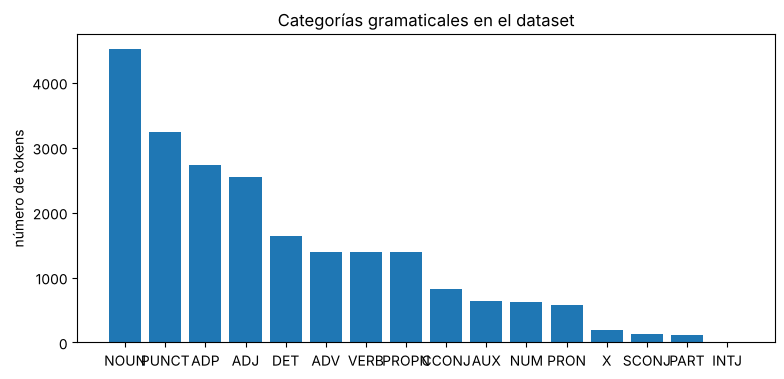

In [18]:
docs = list(nlp.pipe(df["text"]))

conteo_pos = Counter(t.pos_ for d in docs for t in d)
palabras = sum(n for pos, n in conteo_pos.items() if pos != "PUNCT")
print("Tokens:", sum(conteo_pos.values()))
print(f"Palabras no reconocidas (X): {conteo_pos['X'] / palabras:.1%}")
print(f"Stop-words: {sum(t.is_stop for d in docs for t in d) / palabras:.1%}")

etiquetas, cantidades = zip(*conteo_pos.most_common())
plt.figure(figsize=(9, 4))
plt.bar(etiquetas, cantidades)
plt.title("Categorías gramaticales en el dataset")
plt.ylabel("número de tokens")
plt.show()

### Medida del ruido: palabras extranjeras

Aunque ya filtramos los párrafos en otros idiomas, algunos todavía mezclan esperanto con nombres
o títulos en otras lenguas. Con el modelo podemos contar en cada párrafo qué proporción de
palabras no son esperanto (`X`).

In [19]:
def proporcion_extranjeras(doc):
    palabras = [t for t in doc if t.is_alpha]
    return sum(t.pos_ == "X" for t in palabras) / max(len(palabras), 1)


df["extranjeras"] = [proporcion_extranjeras(d) for d in docs]
ruidosos = df[df["extranjeras"] > 0.2]
print(f"Párrafos con más de un 20% de palabras extranjeras: {len(ruidosos)} de {len(df)}")
ruidosos.head(8)

Párrafos con más de un 20% de palabras extranjeras: 3 de 425


,text,class,extranjeras
95,1979 - Japanio-ML500-517 km/h (senhoma) Ĝi suk...,fervojo,0.285714
211,Lexus EV (Featured in the film Minority Report),automobilo,0.250000
409,"Reconocimientos aéreos, captura de datos con s...",aviado,0.250000


### Lemas más frecuentes por clase

Si el modelo funciona bien, los lemas más frecuentes de cada clase (quitando stop-words) deberían
ser claramente de ese tema.

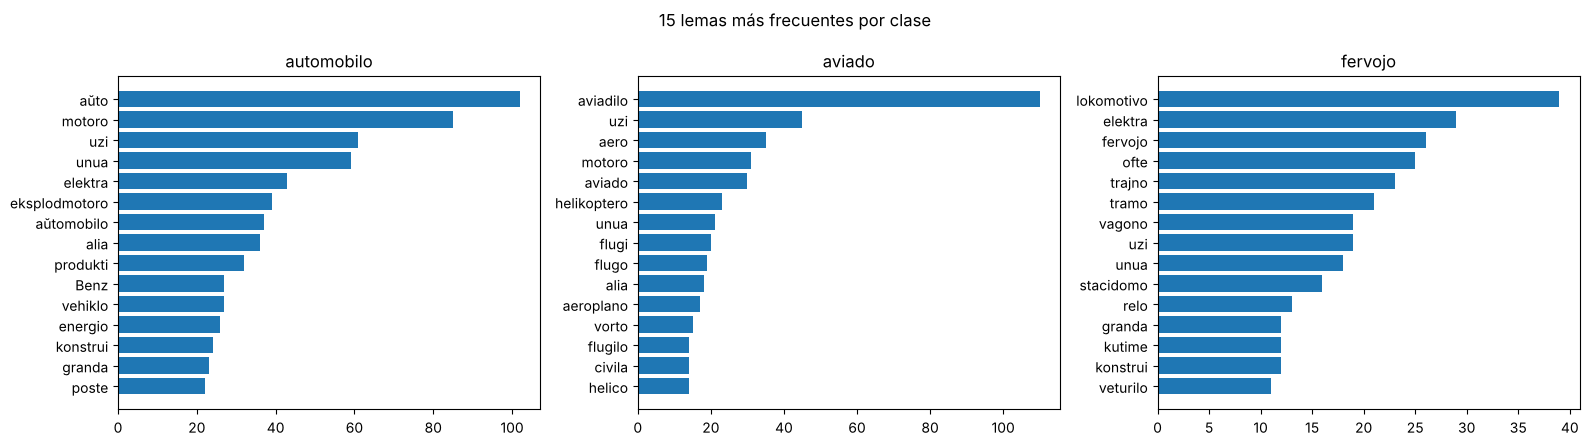

In [20]:
CATEGORIAS_CON_SIGNIFICADO = {"NOUN", "ADJ", "VERB", "PROPN", "ADV"}

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for eje, clase in zip(ejes, sorted(df["class"].unique())):
    conteo = Counter(t.lemma_ for d, c in zip(docs, df["class"]) if c == clase for t in d
                     if t.pos_ in CATEGORIAS_CON_SIGNIFICADO and not t.is_stop and len(t.lemma_) > 2)
    lemas, n = zip(*conteo.most_common(15))
    eje.barh(lemas[::-1], n[::-1])
    eje.set_title(clase)
plt.suptitle("15 lemas más frecuentes por clase")
plt.tight_layout()
plt.show()

### Cuánto reduce el vocabulario la lematización

Con la lematización `trajno`, `trajnoj`, `trajnon` y `trajnojn` pasan a ser una sola palabra. Eso
hace que la matriz de la Fase 3 tenga menos columnas.

In [21]:
formas = {t.text.lower() for d in docs for t in d if t.is_alpha}
lemas = {t.lemma_.lower() for d in docs for t in d if t.is_alpha}
print("Palabras distintas sin lematizar:", len(formas))
print("Lemas distintos:", len(lemas))

Palabras distintas sin lematizar: 5117
Lemas distintos: 3854


## 2.10 Preparación para la Fase 3

`lemas_utiles()` convierte un texto en la lista de lemas que nos interesan: sin stop-words,
puntuación, números ni palabras extranjeras. Se la pasamos a `TfidfVectorizer` de scikit-learn con
`analyzer=lemas_utiles`, así toda la tokenización y lematización la hace nuestro modelo.

In [22]:
def lemas_utiles(texto):
    return [t.lemma_.lower() for t in nlp(texto)
            if not t.is_stop and t.pos_ not in ("PUNCT", "NUM", "X")
            and len(t.lemma_) > 1 and not t.lemma_[0].isdigit()]


print(lemas_utiles(df["text"].iloc[0]))

['fervojo', 'transportsistemo', 'veturilo', 'moviĝi', 'rado', 'relo', 'sekurigado', 'respondi', 'atingebla', 'granda', 'kineta', 'energio', 'trajno', 'peli', 'dekomence', 'vapormaŝino', 'precipe', 'elektra', 'termika', 'motoro']


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizador = TfidfVectorizer(analyzer=lemas_utiles, min_df=2)
X = vectorizador.fit_transform(df["text"])
print("Matriz TF-IDF:", X.shape, "(párrafos x lemas)")

Matriz TF-IDF: (425, 1373) (párrafos x lemas)


# Fase 3 · Clasificación

## 3.1 Separación en entrenamiento y test

Separamos un 20% de los párrafos para el test final, de forma **estratificada** (con la misma
proporción de cada clase en los dos trozos, porque las clases no están equilibradas). Fijamos la
semilla para que el resultado sea siempre el mismo.

El vectorizador y el modelo los metemos en un `Pipeline` de scikit-learn. Así el vocabulario del
TF-IDF se aprende solo con los textos de entrenamiento y el test no influye en nada.

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEMILLA = 42

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["class"], test_size=0.2, stratify=df["class"], random_state=SEMILLA)

print("Entrenamiento:", len(X_train), " Test:", len(X_test))

Entrenamiento: 340  Test: 85


## 3.2 Elección del vectorizador y del modelo

Probamos dos formas de vectorizar y tres modelos, todos rápidos y sin GPU:

* **Bag of Words** (`CountVectorizer`): cuántas veces aparece cada lema en el párrafo.
* **TF-IDF**: igual, pero da más peso a los lemas que aparecen en pocos párrafos (`lokomotivo`)
  y menos a los que salen en casi todos (`veturilo`).
* Modelos: **Naive Bayes**, **Regresión Logística** y **SVM lineal**. En los dos últimos usamos
  `class_weight="balanced"` para compensar que hay menos párrafos de trenes.

Los comparamos con **validación cruzada de 5 particiones** sobre el entrenamiento, usando el
**F1 macro** (la media del F1 de cada clase), que no se deja engañar por la clase mayoritaria.

In [25]:
modelos = {
    "Naive Bayes": MultinomialNB(),
    "Regresión Logística": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "SVM lineal": LinearSVC(class_weight="balanced"),
}
vectorizadores = {"Bag of Words": CountVectorizer, "TF-IDF": TfidfVectorizer}
particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

comparacion = []
for nombre_vec, Vectorizador in vectorizadores.items():
    for nombre_mod, modelo in modelos.items():
        pipeline = make_pipeline(Vectorizador(analyzer=lemas_utiles, min_df=2), modelo)
        f1 = cross_val_score(pipeline, X_train, y_train, cv=particiones, scoring="f1_macro")
        comparacion.append({"vectorizador": nombre_vec, "modelo": nombre_mod,
                            "F1 macro (media)": round(f1.mean(), 3), "desviación": round(f1.std(), 3)})

pd.DataFrame(comparacion).sort_values("F1 macro (media)", ascending=False)

,vectorizador,modelo,F1 macro (media),desviación
4,TF-IDF,Regresión Logística,0.906,0.025
5,TF-IDF,SVM lineal,0.905,0.025
0,Bag of Words,Naive Bayes,0.894,0.024
1,Bag of Words,Regresión Logística,0.864,0.018
2,Bag of Words,SVM lineal,0.839,0.044
3,TF-IDF,Naive Bayes,0.805,0.044


Nos quedamos con **TF-IDF + Regresión Logística**: tiene el mejor F1 macro, prácticamente empatado
con la SVM, pero además da probabilidades por clase (`predict_proba`), que necesitamos para
clasificar las páginas web.

Curiosamente, Naive Bayes funciona bien con Bag of Words y mal con TF-IDF: con TF-IDF tiende a
meter casi todo en la clase mayoritaria (`automobilo`).

## 3.3 Entrenamiento y evaluación en test

Accuracy: 0.941
F1 macro: 0.937

              precision    recall  f1-score   support

  automobilo       0.95      0.95      0.95        41
      aviado       0.96      0.96      0.96        24
     fervojo       0.90      0.90      0.90        20

    accuracy                           0.94        85
   macro avg       0.94      0.94      0.94        85
weighted avg       0.94      0.94      0.94        85



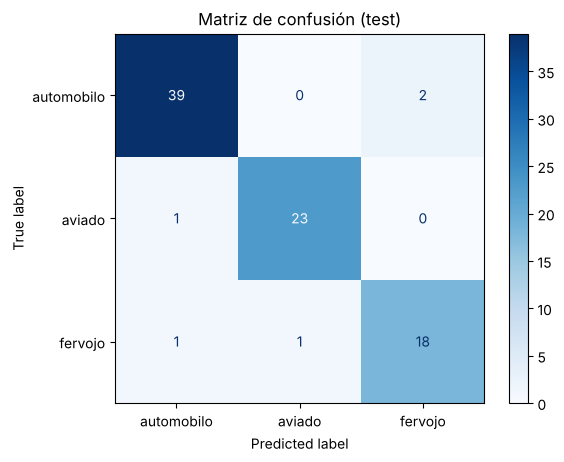

In [26]:
modelo = make_pipeline(
    TfidfVectorizer(analyzer=lemas_utiles, min_df=2),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"F1 macro: {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión (test)")
plt.show()

### Párrafos mal clasificados

Revisar los errores ayuda a entender qué le cuesta al modelo. Muchos son párrafos genéricos que
podrían ser de cualquier tema, es decir, el ruido de etiquetado del que hablábamos en la Fase 1.

In [27]:
errores = pd.DataFrame({"text": X_test, "real": y_test, "predicho": y_pred})
errores = errores[errores["real"] != errores["predicho"]]
pd.set_option("display.max_colwidth", 150)
errores

,text,real,predicho
277,Antaŭ aŭ post la veturo la uzanto pagas al la stiristo por la veturo.,automobilo,fervojo
5,Internacia Asocio de Esperantistaj Fervojistoj (ekde 1909 ĝis Dua Mondmilito),fervojo,aviado
186,"Laŭ diversaj fontoj, la unua elektra veturilo estis konstruita en 1839 fare de Robert Anderson en Aberdeen, Skotlando.",automobilo,fervojo
422,Oni notas ke aerostatiko estas simile kun aerodinamiko parto de meĥaniko de fluidoj.,aviado,automobilo
52,"Kelkaj urboj uzis sian tramsistemon por la transporto ne nur de pasaĝeroj, sed ankaŭ de varoj, ekzemple poŝtaĵoj. Tiu uzo tamen pliparte malaperis...",fervojo,automobilo


### Palabras que más pesan en cada clase

La Regresión Logística aprende un peso para cada lema y clase. Los lemas con más peso son los que
más empujan un texto hacia esa clase.

In [28]:
vocabulario = modelo[0].get_feature_names_out()
regresion = modelo[1]

for i, clase in enumerate(regresion.classes_):
    mejores = regresion.coef_[i].argsort()[::-1][:12]
    print(f"{clase:<11}", ", ".join(vocabulario[j] for j in mejores))

automobilo  aŭto, aŭtomobilo, aŭtovojo, eksplodmotoro, motorciklo, aŭtobuso, kamiono, motoro, produkti, benz, taksio, lando
aviado      aviadilo, aviado, helikoptero, rotoro, aerŝipo, aero, flugi, flughaveno, levoforto, flugilo, balono, avio
fervojo     lokomotivo, stacidomo, trajno, fervojo, tramo, vagono, ofte, fervoja, fervojista, trako, metroo, relo


**Limitación.** Los párrafos de un mismo artículo pueden caer unos en entrenamiento y otros en
test. Como comparten vocabulario muy concreto, el resultado en test probablemente es algo
optimista. Para evitarlo habría que separar por artículo, pero el contrato de datos solo permite
las columnas `text;class`.

## 3.4 Clasificación de páginas web

Descargamos páginas reales en esperanto con `requests`, sacamos el texto de los párrafos (`<p>`)
con BeautifulSoup y le pedimos al modelo la probabilidad de cada clase. Si una página no responde,
se avisa y se sigue con las demás.

In [29]:
from bs4 import BeautifulSoup

PAGINAS = [
    "https://www.flightschoolusa.com/eo/kiom-gajnas-atc/",
    "https://eo.wikipedia.org/wiki/Transsiberia_fervojo",
    "https://eo.wikipedia.org/wiki/Formulo_1",
]


def texto_de_pagina(url):
    respuesta = requests.get(url, headers={"User-Agent": "practica-mineria-textos-cunef"}, timeout=15)
    respuesta.raise_for_status()
    sopa = BeautifulSoup(respuesta.text, "html.parser")
    for etiqueta in sopa(["script", "style", "nav", "header", "footer", "aside"]):
        etiqueta.decompose()
    parrafos = [limpiar_parrafo(p.get_text(" ")) for p in sopa.find_all("p")]
    return " ".join(p for p in parrafos if len(p) >= LONGITUD_MINIMA)


resultados_web = []
for url in PAGINAS:
    try:
        texto = texto_de_pagina(url)
        if not texto:
            raise ValueError("la página no tiene párrafos de texto")
    except Exception as e:
        print(f"No se pudo descargar {url}: {e}")
        continue
    probabilidades = modelo.predict_proba([texto])[0]
    fila = {"página": url, "palabras": len(texto.split())}
    fila.update({clase: round(p, 3) for clase, p in zip(modelo.classes_, probabilidades)})
    fila["predicción"] = modelo.classes_[probabilidades.argmax()]
    resultados_web.append(fila)

pd.DataFrame(resultados_web)

No se pudo descargar https://www.flightschoolusa.com/eo/kiom-gajnas-atc/: HTTPSConnectionPool(host='www.flightschoolusa.com', port=443): Max retries exceeded with url: /eo/kiom-gajnas-atc/ (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden (agent proxy: no rule or network setting allows this host)')))
No se pudo descargar https://eo.wikipedia.org/wiki/Transsiberia_fervojo: HTTPSConnectionPool(host='eo.wikipedia.org', port=443): Max retries exceeded with url: /wiki/Transsiberia_fervojo (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden (agent proxy: no rule or network setting allows this host)')))
No se pudo descargar https://eo.wikipedia.org/wiki/Formulo_1: HTTPSConnectionPool(host='eo.wikipedia.org', port=443): Max retries exceeded with url: /wiki/Formulo_1 (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden (agent proxy: no rule or netwo

""


### Textos escritos por nosotros

Por último probamos el modelo con unas frases nuestras. También sirve para comprobar que el
modelo funciona aunque no haya conexión.

In [30]:
textos_propios = [
    "La trajno alvenis al la stacidomo kun duonhora malfruo pro problemo en la reloj.",
    "Mia nova elektra aŭto bezonas nur unu horon por ŝargi la baterion.",
    "La piloto anoncis, ke la aviadilo surteriĝos en la flughaveno post dek minutoj.",
    "La ŝoforo de la kamiono ne vidis la buson sur la aŭtovojo.",
]

probabilidades = modelo.predict_proba(textos_propios)
tabla = pd.DataFrame(probabilidades.round(3), columns=modelo.classes_)
tabla.insert(0, "texto", textos_propios)
tabla["predicción"] = modelo.predict(textos_propios)
tabla

,texto,automobilo,aviado,fervojo,predicción
0,La trajno alvenis al la stacidomo kun duonhora malfruo pro problemo en la reloj.,0.087,0.072,0.842,fervojo
1,Mia nova elektra aŭto bezonas nur unu horon por ŝargi la baterion.,0.631,0.154,0.216,automobilo
2,"La piloto anoncis, ke la aviadilo surteriĝos en la flughaveno post dek minutoj.",0.149,0.646,0.205,aviado
3,La ŝoforo de la kamiono ne vidis la buson sur la aŭtovojo.,0.752,0.108,0.140,automobilo


## Conclusiones

* El dataset tiene bastante ruido: casi un tercio de lo que devuelve la Wikipedia son listas,
  bibliografía o texto en otros idiomas, y lo filtramos con reglas sencillas.
* Nuestro modelo de NLP, solo con reglas, acierta alrededor del 96% de las categorías gramaticales
  y del 97% de los lemas en frases reales.
* Con TF-IDF sobre los lemas y una Regresión Logística, el clasificador consigue un F1 macro
  alrededor de 0,9 en validación cruzada y en test.
* Lo que más se podría mejorar es el dataset: más párrafos de trenes y de aviación, y una forma de
  detectar los párrafos genéricos que heredan una etiqueta que no les corresponde.